# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Python/Data/yulu_rental.csv')

In [3]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [5]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

In [6]:
df.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4


## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10886 entries, 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   season       10886 non-null  int64  
 1   holiday      10886 non-null  int64  
 2   workingday   10886 non-null  int64  
 3   weather      10886 non-null  int64  
 4   temp         10886 non-null  float64
 5   atemp        10886 non-null  float64
 6   humidity     10886 non-null  int64  
 7   windspeed    10886 non-null  float64
 8   casual       10886 non-null  int64  
 9   registered   10886 non-null  int64  
 10  count        10886 non-null  int64  
 11  date         10886 non-null  object 
 12  day          10886 non-null  int32  
 13  week         10886 non-null  UInt32 
 14  weekday_num  10886 non-null  int32  
 15  weekday      10886 non-null  object 
 16  year         10886 non-null  int32  
 17  month        10886 non-null  int32  
 18  hour       

In [8]:
df['day'].max()   # 19

19

**Висновок**

1. У наборі 10886 рядків та 19 колонок, пропусків немає.
2. Дані за період 2011-01-01 по 2012-12-19, тобто майже 2 роки.
3. Рівень деталізації - 1 рядок = 1 година.
4. Index має формат дата + година.
5. Дані не за кожен день, а тільки за 1-19 число кожного місяця.




## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


In [9]:
daily = df['count'].resample('D').sum()

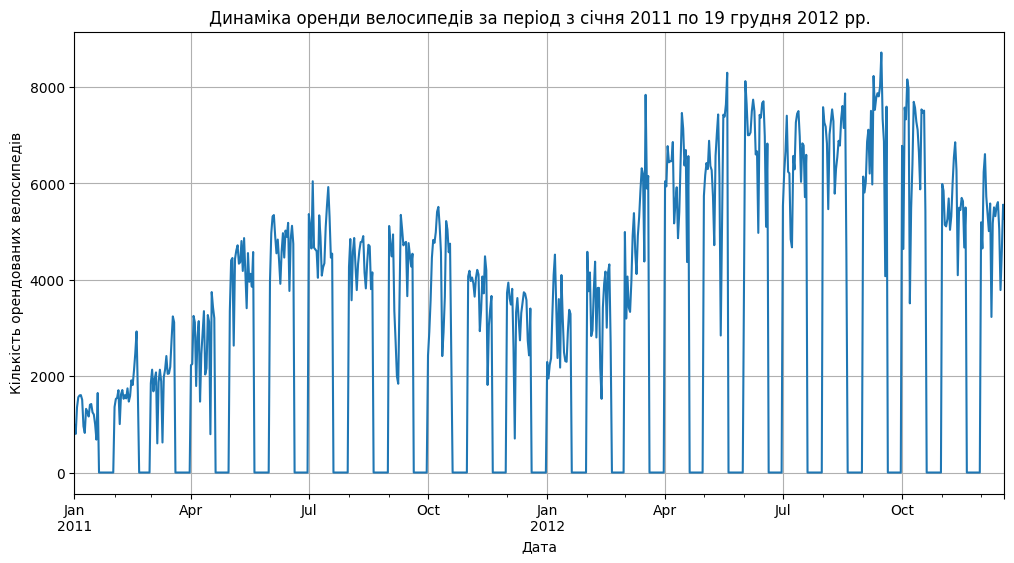

In [10]:
daily.plot.line(
    figsize=(12,6),
    title='Динаміка оренди велосипедів за період з січня 2011 по 19 грудня 2012 рр.',
    xlabel='Дата',
    ylabel='Кількість орендованих велосипедів',
    grid=True);

**Відповіді**
1. Заломи. У даних є тільки 1–19 число кожного місяця. Без даних за 20–31 число графік щомісяця падає до 0, створюючи заломи. Прибрати заломи можна через min_count=1: пропущені дні тепер NaN, і лінія розривається.
2. Тенденції. Оренда росте: у 2012 році значення помітно вищі, ніж у 2011.
Сезонність. Є: взимку оренд мало, навесні вони ростуть, влітку й на початку осені найбільше, у листопаді–грудні знову спад.
3. Аномалії. Є окремі дні з дуже низькими значеннями. Причини — погана погода (злива, шторм) або свята.

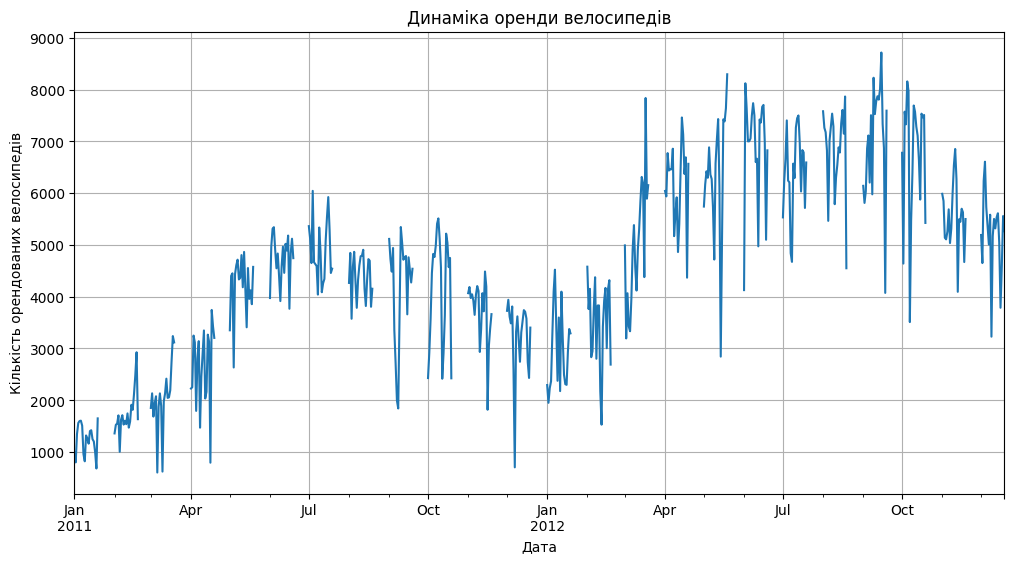

In [11]:
df['count'].resample('D').sum(min_count=1).plot(   # сума за кожен день
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    xlabel='Дата',
    ylabel='Кількість орендованих велосипедів',
    grid=True
);

In [12]:
real_days = daily[daily > 0]                 # прибираємо порожні дні (20–31 число)
worst = real_days.nsmallest(5)               # 5 найгірших справжніх днів
weather = df.resample('D')['weather'].max().loc[worst.index]   # погода в ці найгірші 5 днів

pd.DataFrame({'count': worst, 'weather': weather}) #

,count,weather
datetime,,
2011-03-06,605,3.0
2011-03-10,623,3.0
2011-01-18,683,2.0
2011-12-07,705,3.0
2011-04-16,795,3.0



## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

In [35]:
quarter_names = {1: 'Q1 (січ–бер)', 2: 'Q2 (кві–чер)', 3: 'Q3 (лип–вер)', 4: 'Q4 (жов–гру)'}
season_avg_by = df.groupby(['season', 'year'])['count'].mean().unstack().rename(quarter_names)
season_avg_by

year,2011,2012
season,,
Q1 (січ–бер),71.905518,159.476889
Q2 (кві–чер),160.940746,269.601757
Q3 (лип–вер),186.994872,281.735380
Q4 (жов–гру),154.787125,243.189466


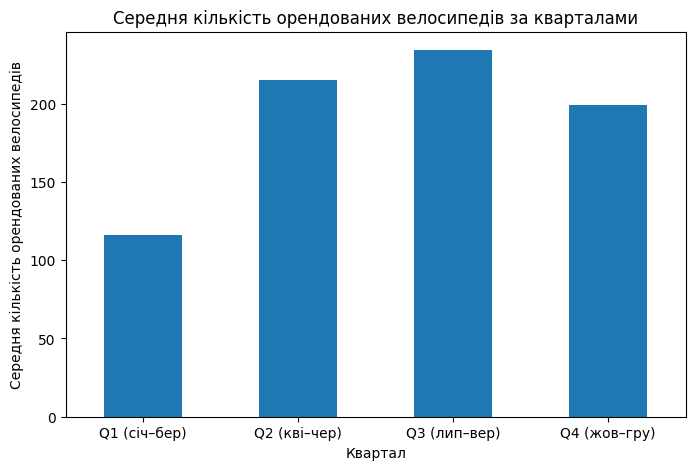

In [24]:
ax = season_avg.plot.bar(
    figsize=(8,5),
    title='Середня кількість орендованих велосипедів за кварталами',
    xlabel='Квартал',
    ylabel='Середня кількість орендованих велосипедів',
    rot=0
);


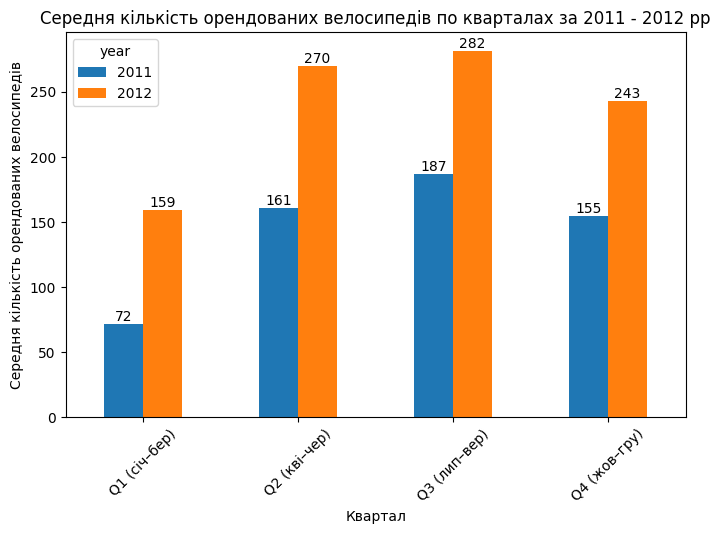

In [37]:
ax = season_avg_by.plot.bar(
    figsize=(8,5),
    title='Середня кількість орендованих велосипедів по кварталах за 2011 - 2012 рр',
    xlabel='Квартал',
    ylabel='Середня кількість орендованих велосипедів'
)
plt.xticks(rotation=45)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f');     # підписи над усіма стовпцями

In [39]:
season_avg.max() / season_avg.min()

2.0148749597441986

## Відповіді
**1. Найбільша середня оренда** — у **Q3 (липень–вересень)** 187 і 282. Q2 - теж має досить високе середнє.
Найменша — у **Q1 (січень–березень)**: 72 і 159.

**2. Пояснення:** у Q3 - Q2 тепло й сухо, тому люди частіше їздять на велосипедах.
У Q1 холодно, буває сніг і дощ, тому оренда найнижча. Q4 — перехідний сезон і оренда середня.

**3. Різниця між Q3 і Q1:**
- 2011: 187 / 72 ≈ **2.6 раза**
- 2012: 282 / 159 ≈ **1.8 раза**
- за 2 роки разом: ≈ **2 рази**

**Додатково:** у 2012 році оренда вища в кожному кварталі, тобто сервіс росте.
У Q1 вона зросла найбільше (72 → 159, більш ніж удвічі).

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


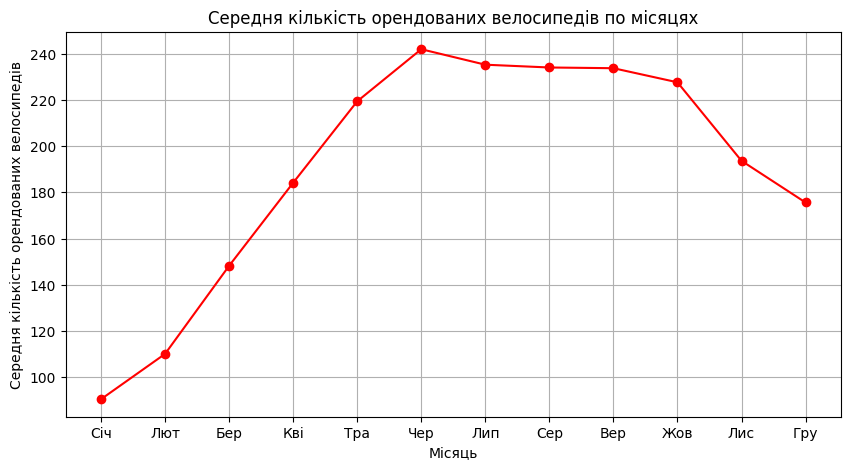

In [48]:
ax = df.groupby('month')['count'].mean().plot(
    figsize=(10,5),
    title='Середня кількість орендованих велосипедів по місяцях',
    xlabel='Місяць',
    ylabel='Середня кількість орендованих велосипедів',
    marker='o',
    grid=True,
    color='red'
)
ax.set_xticks(range(1, 13), ['Січ','Лют','Бер','Кві','Тра','Чер','Лип','Сер','Вер','Жов','Лис','Гру']);

## Відповіді
**1. Пік і спад:**
- Пік — **червень** (~242 оренди за годину). Високий рівень тримається з червня по жовтень (228–242).
- Спад — січень, далі лютий. Після жовтня оренда знову падає.

**2. Збіг з попереднім завданням:** так. Найвищий квартал Q3 (липень–вересень) — це місяці «плато» на графіку,
а найнижчий Q1 (січень–березень) — найнижчі точки.
Помісячний графік показує точніше: найвищий окремий місяць — червень (Q2). Але Q2 загалом нижчий за Q3,
бо в нього входить квітень, коли сезон ще тільки починається.

**3. Вплив клімату:** у теплі місяці (травень–жовтень) кататися комфортно, тому оренда висока.
Взимку холодно, бувають сніг і ожеледь, тому оренд у 2–2.5 раза менше.
Навесні оренда плавно росте разом із температурою, а восени плавно падає.
Отже, головний фактор сезонності — температура й погода.

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

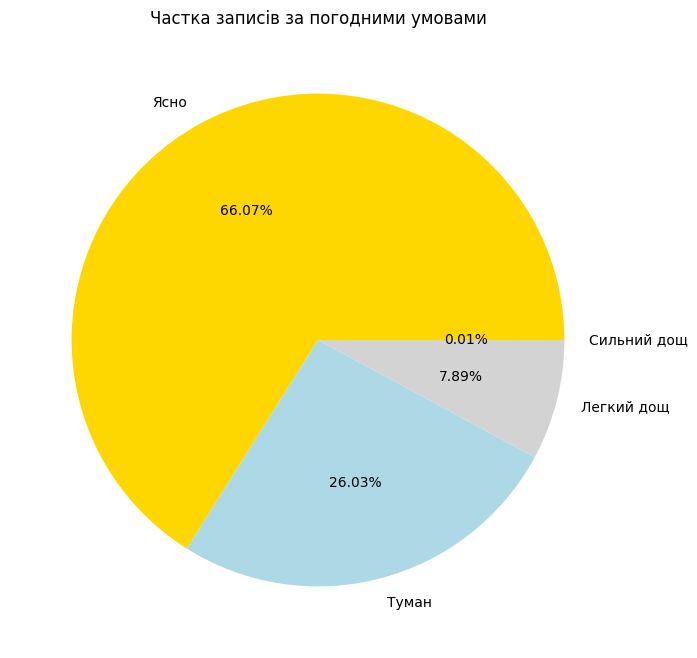

In [56]:
import numpy as np

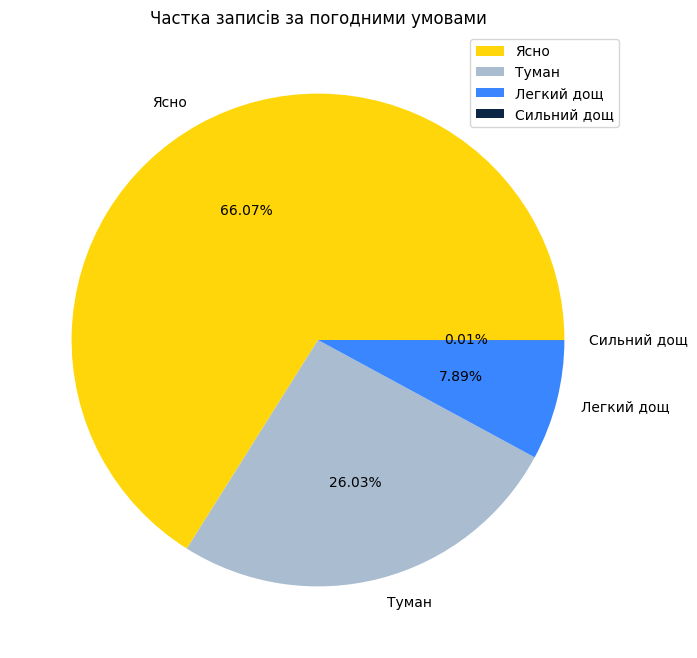

In [66]:
ax = df['weather'].value_counts().sort_index().rename({1:'Ясно', 2:'Туман', 3:'Легкий дощ', 4:'Сильний дощ'}).plot.pie(
    figsize=(8,8),
    autopct='%1.2f%%', # відсотки
    title='Частка записів за погодними умовами',
    colors=['#FFD60A', '#A9BCD0', '#3A86FF', '#0B2545'], # мої кольори
    ylabel='' # прибираємо підпис Y
)
ax.legend();

In [60]:
df['weather'].value_counts()

,count
weather,
1,7192
2,2834
3,859
4,1


In [67]:
df.groupby('weather')['count'].mean()

,count
weather,
1,205.236791
2,178.955540
3,118.846333
4,164.000000


## Відповіді
**1.** Переважає **ясна погода** — 66% записів. Ще 26% — туман/хмарно.

**2.** Сильний дощ є, але це рідкість — **0.01%**, тобто лише 1 запис (1 година) з 10 886.
Легкий дощ — 7.9%.

**3.** Чим гірша погода, то менше оренд: у дощ і туман кататися незручно й небезпечно.
У ясну погоду попит найвищий.
Важливо: тут показана частка годин з такою погодою, а не кількість оренд.

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

In [77]:
df[:4]

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour,weather_name
datetime,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0,Ясно
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1,Ясно
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2,Ясно
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3,Ясно


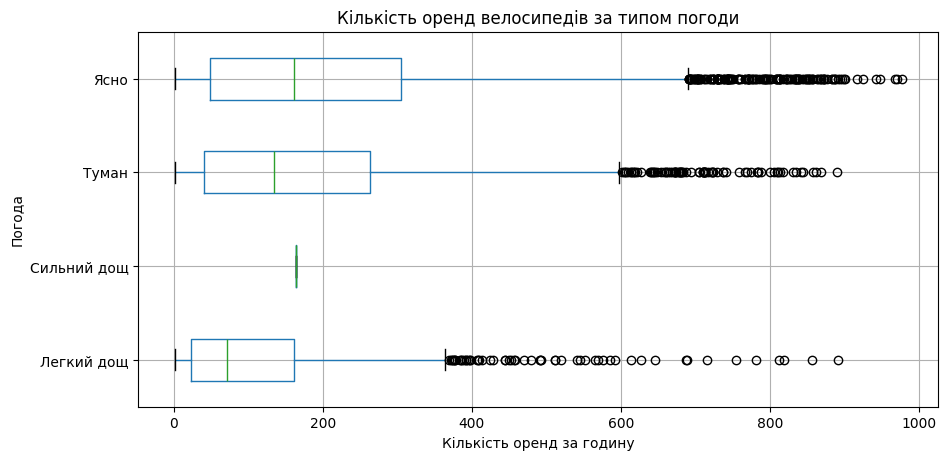

In [79]:
weather_type = {1: 'Ясно', 2: 'Туман', 3: 'Легкий дощ', 4: 'Сильний дощ'}
df['weather_name'] = df['weather'].map(weather_type)    # створюємо колонку з назвами

ax = df.boxplot(
    column='count',
    by='weather_name',
    figsize=(10, 5),
    grid=True,
    vert=False # горизонтально
)
plt.suptitle('')
ax.set_title('Кількість оренд велосипедів за типом погоди')
ax.set_xlabel('Кількість оренд за годину')
ax.set_ylabel('Погода');


**1. Найбільший розкид** — у **ясну погоду**: коробка найширша (≈ 50–300 оренд за годину), а «вус» тягнеться до ~700.
Найменший розкид — у легкий дощ.

**2. Викиди є** при ясній погоді, тумані й легкому дощі. Це кружечки праворуч: до ~980 оренд у ясну погоду, до ~900 у туман і в легкий дощ.
Найімовірніше, це не помилки, а **години пік** (дорога на роботу й назад), коли попит різко зростає.

**3. Найвища медіана** — у **ясну погоду** (≈ 160). Далі туман (≈ 135) і легкий дощ (≈ 70).

**Примітка:** «Сильний дощ» — лише 1 запис, тому замість коробки там одна лінія, і висновків про нього робити не можна.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

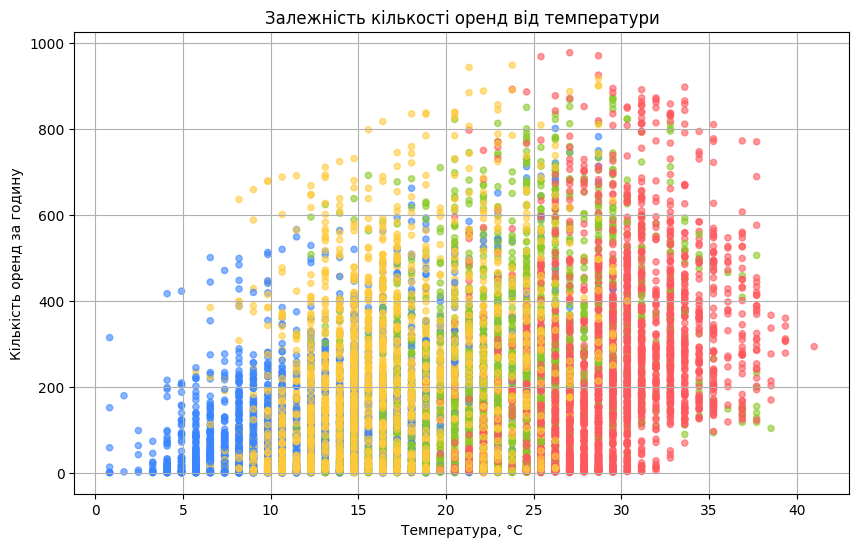

In [84]:
quarter_names = {1: 'Q1 (січ–бер)', 2: 'Q2 (кві–чер)', 3: 'Q3 (лип–вер)', 4: 'Q4 (жов–гру)'}
season_colors = {1: '#3A86FF', 2: '#8AC926', 3: '#FF595E', 4: '#FFCA3A'}
df.plot.scatter(
    x='temp',
    y='count',
    c=df['season'].map(season_colors),
    alpha=0.6,
    figsize=(10, 6),
    title='Залежність кількості оренд від температури',
    grid=True
)
plt.xlabel('Температура, °C')
plt.ylabel('Кількість оренд за годину');

In [85]:
df['temp'].corr(df['count'])

np.float64(0.394453644967249)

**Висновок:** між температурою та кількістю оренд є **помірний позитивний зв'язок** (кореляція = 0.39).
Що тепліше, то більше людей орендують велосипеди: у холодні години (Q1) оренд мало, а в теплі (Q3) їх більше.
Але зв'язок не сильний, бо на оренду впливають ще й інші фактори: **година доби** (вночі оренд мало навіть коли тепло), погода, вихідний чи робочий день.
У сильну спеку (35°C+) оренда трохи падає.

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

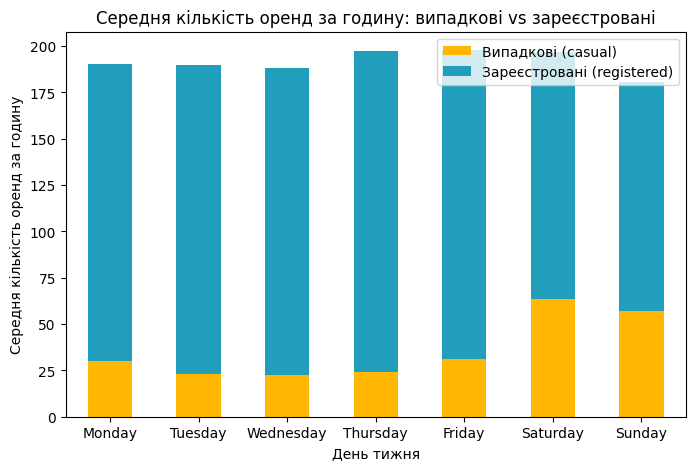

In [89]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

users_by_day = df.groupby('weekday')[['casual', 'registered']].mean().reindex(days)

ax = users_by_day.plot.bar(
    stacked=True,
    figsize=(8, 5),
    color=['#FFB703', '#219EBC'],
    title='Середня кількість оренд за годину: випадкові vs зареєстровані',
    xlabel='День тижня',
    ylabel='Середня кількість оренд за годину',
    rot=0
)
ax.legend(['Випадкові (casual)', 'Зареєстровані (registered)']);

**1.** Зареєстровані користувачі беруть більше велосипедів **у будні (пн–пт)**: ≈ 160–170 оренд за годину. У вихідні їхня кількість менша: ≈ 130.

**2. Пояснення:**
- **Зареєстровані** — переважно люди, які їздять **на роботу чи навчання**. Тому вони активні в будні, а у вихідні їх менше.
- **Випадкові** — це туристи та люди, які катаються **для відпочинку**. Тому у вихідні їх удвічі більше.
- Загальна кількість оренд за день майже однакова (~190–200), але **склад користувачів різний**:
  у будні велосипед — це транспорт, а у вихідні — розвага.